In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Step 1: Load the dataset, skipping any malformed rows
df_simple = pd.read_csv("Invistico_Airline.csv", on_bad_lines='skip')
print("Dataset Shape:", df_simple.shape)


Dataset Shape: (129880, 23)


In [6]:
# Step 2: Handle missing values simply
for col in df_simple.columns:
    if df_simple[col].dtype in ['float64', 'int64']:
        df_simple[col] = df_simple[col].fillna(df_simple[col].mean())

# Step 3: Convert the target column 'satisfaction' to 1 (satisfied) and 0 (dissatisfied)
df_simple['satisfaction'] = df_simple['satisfaction'].map({'satisfied': 1, 'dissatisfied': 0})


In [7]:
# Step 4: Convert categorical text columns into 1s and 0s using pd.get_dummies
df_encoded = pd.get_dummies(df_simple, columns=['Gender', 'Customer Type', 'Type of Travel', 'Class'], drop_first=True)


In [8]:
# Step 5: Separate features (X) and target label (y)
y_data = df_encoded['satisfaction']
X_data = df_encoded.drop(columns=['satisfaction'])


In [9]:
# Step 6: Split the data FIRST
X_train, X_test, y_train, y_test = train_test_split(
    X_data,
    y_data,
    test_size=0.2,
    random_state=42,
    stratify=y_data
)


In [10]:
# Step 7: Scale AFTER splitting
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)


# Step 8: Train Logistic Regression
simple_model = LogisticRegression(
    solver='liblinear',
    random_state=42
)

simple_model.fit(X_train_scaled, y_train)



LogisticRegression(random_state=42, solver='liblinear')

In [11]:
# Step 9: Measure the performance
train_acc = simple_model.score(X_train, y_train)
test_acc = simple_model.score(X_test, y_test)

print(f"Training Accuracy: {train_acc * 100:.2f}%")
print(f"Testing Accuracy: {test_acc * 100:.2f}%")


Training Accuracy: 45.30%
Testing Accuracy: 45.31%


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


=== Performance Metrics ===
Accuracy:  45.31%
Precision: 100.00%
Recall:    0.07%



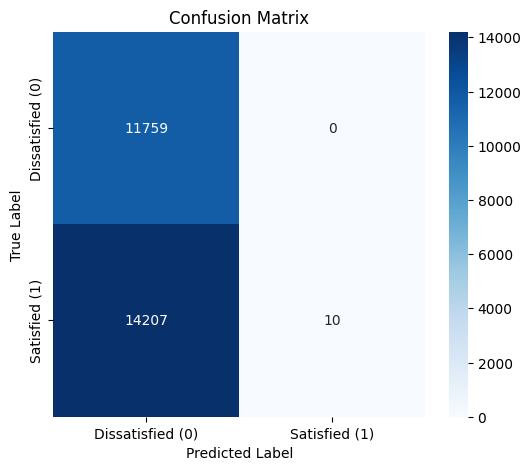

In [12]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Get predictions on the test dataset
y_pred = simple_model.predict(X_test)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print("=== Performance Metrics ===")
print(f"Accuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print("============================\n")

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot the Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Dissatisfied (0)', 'Satisfied (1)'],
    yticklabels=['Dissatisfied (0)', 'Satisfied (1)']
)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [14]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import pandas as pd

# Ensure the previous steps have been run first
try:
    feature_columns = list(X_data.columns)
except NameError:
    print("WARNING: Please run all previous cells (Steps 1 to 9) first to load variables!")
    feature_columns = [
        'Age', 'Flight Distance', 'Departure Delay in Minutes', 'Arrival Delay in Minutes',
        'Gender_Male', 'Customer Type_disloyal Customer', 'Type of Travel_Personal Travel',
        'Class_Eco', 'Class_Eco Plus'
    ]

# Create the Input Widgets
gender_w = widgets.Dropdown(options=['Female', 'Male'], description='Gender:')
customer_type_w = widgets.Dropdown(options=['Loyal Customer', 'disloyal Customer'], description='Cust Type:')
travel_type_w = widgets.Dropdown(options=['Business travel', 'Personal Travel'], description='Travel Type:')
travel_class_w = widgets.Dropdown(options=['Business', 'Eco', 'Eco Plus'], description='Class:')
age_w = widgets.IntSlider(min=0, max=100, step=1, value=35, description='Age:')
flight_distance_w = widgets.IntSlider(min=0, max=5000, step=50, value=1000, description='Distance:')
departure_delay_w = widgets.IntSlider(min=0, max=1440, step=5, value=0, description='Dep Delay:')
arrival_delay_w = widgets.IntSlider(min=0, max=1440, step=5, value=0, description='Arr Delay:')

# Create a Predict Button and an Output area
predict_button = widgets.Button(description="Predict Satisfaction", button_style='primary')
output_area = widgets.Output()

def on_predict_clicked(b):
    with output_area:
        clear_output()

        # Check if model and scaler are loaded in memory
        if 'scaler' not in globals() or 'simple_model' not in globals():
            print("Error: 'scaler' or 'simple_model' not found. Please run the training cells first.")
            return

        # 1. Create input row matching feature_columns structure
        input_data = {col: 0.0 for col in feature_columns}

        # 2. Fill numerical features
        input_data['Age'] = float(age_w.value)
        input_data['Flight Distance'] = float(flight_distance_w.value)
        input_data['Departure Delay in Minutes'] = float(departure_delay_w.value)
        input_data['Arrival Delay in Minutes'] = float(arrival_delay_w.value)

        # 3. Handle categorical dummies
        if gender_w.value == 'Male':
            input_data['Gender_Male'] = 1.0
        if customer_type_w.value == 'disloyal Customer':
            input_data['Customer Type_disloyal Customer'] = 1.0
        if travel_type_w.value == 'Personal Travel':
            input_data['Type of Travel_Personal Travel'] = 1.0
        if travel_class_w.value == 'Eco':
            input_data['Class_Eco'] = 1.0
        elif travel_class_w.value == 'Eco Plus':
            input_data['Class_Eco Plus'] = 1.0

        # 4. Prepare data and scale
        input_row = pd.DataFrame([input_data])[feature_columns]
        input_scaled = scaler.transform(input_row)

        # 5. Get model prediction
        prediction = simple_model.predict(input_scaled)[0]
        probability = simple_model.predict_proba(input_scaled)[0][1]

        # 6. Display formatting
        print("\n================ RESULT ================")
        if prediction == 1:
            print(f"Prediction: SATISFIED (Confidence: {probability * 100:.1f}%)")
        else:
            print(f"Prediction: DISSATISFIED (Confidence: {(1 - probability) * 100:.1f}%)")
        print("========================================")

# Link the button click to our function
predict_button.on_click(on_predict_clicked)

# Display everything in a clean layout
input_container = widgets.VBox([
    gender_w, customer_type_w, travel_type_w, travel_class_w,
    age_w, flight_distance_w, departure_delay_w, arrival_delay_w,
    predict_button, output_area
])
display(input_container)